**DADS – Week 5 Exploratory Exercise** | **Name:** Dushyant S. Shekhawat | **Roll No.:** E26133031

**Q1. Embedding video and images in a notebook** (video: `rabbit320.mp4`, a 7.8 s clip of a toy rabbit, 320×240, 234 frames, 0.83 MB, from MDN's learning-area examples on GitHub, CC0) https://github.com/mdn/learning-area/blob/main/html/multimedia-and-embedding/video-and-audio-content/rabbit320.mp4

- **Format:** `Video("f.mp4", embed=True)` converts the MP4 bytes into **base64 text** and saves it inside HTML:  
`<video><source src="data:video/mp4;base64,AAAAGGZ0eXBtcDQy…">`  
Base64 uses 64 characters (`A–Z a–z 0–9 + /`). Every 3 bytes become 4 characters, so the text is **33% larger** (834,563 bytes → 1,112,752 characters). Each character holds 6 bits, so changing one character changes only one byte of the video. **Note: 24 bits = 3 byte = 4 Base64 Characters.**
- **Altering characters:**  
-- Altering a character to an **invalid** base64 character (e.g. `!`) makes the base64 decoding fail, so the embedded text cannot be turned back into a video and nothing plays  
--Replacing a character with another **valid** base64 character still decodes, but the effect depends on *where* the change is: in the header/index it can make the video non-playable; in the frame data the video can freeze or show glitches; in non-critical parts (e.g. metadata text) there is no visible change. The test below confirms this, with 5 random runs for each k, where k is the number of base64 characters changed in the video's embedded text.

What one change is: a randomly chosen character is swapped for a different valid base64 character, e.g. G becomes x.
k = 1, 10, 100: 1, 10 or 100 such changes, all within one part of the video (header, frame data or metadata text).
5 runs: for each k, different random positions were picked 5 times, which is why results are reported as “4 of 5” and so on.
The k = 33 case: the metadata text is only 33 characters long, so “k = 100” there was capped at 33, meaning every character of it was changed.

Each base64 character holds 6 bits of the file, so k changed characters means about k bytes of the video were altered. k = 100 is only 0.009% of the 1,112,752 characters, yet it was enough to stop the video playing when it hit the header or the frame data.

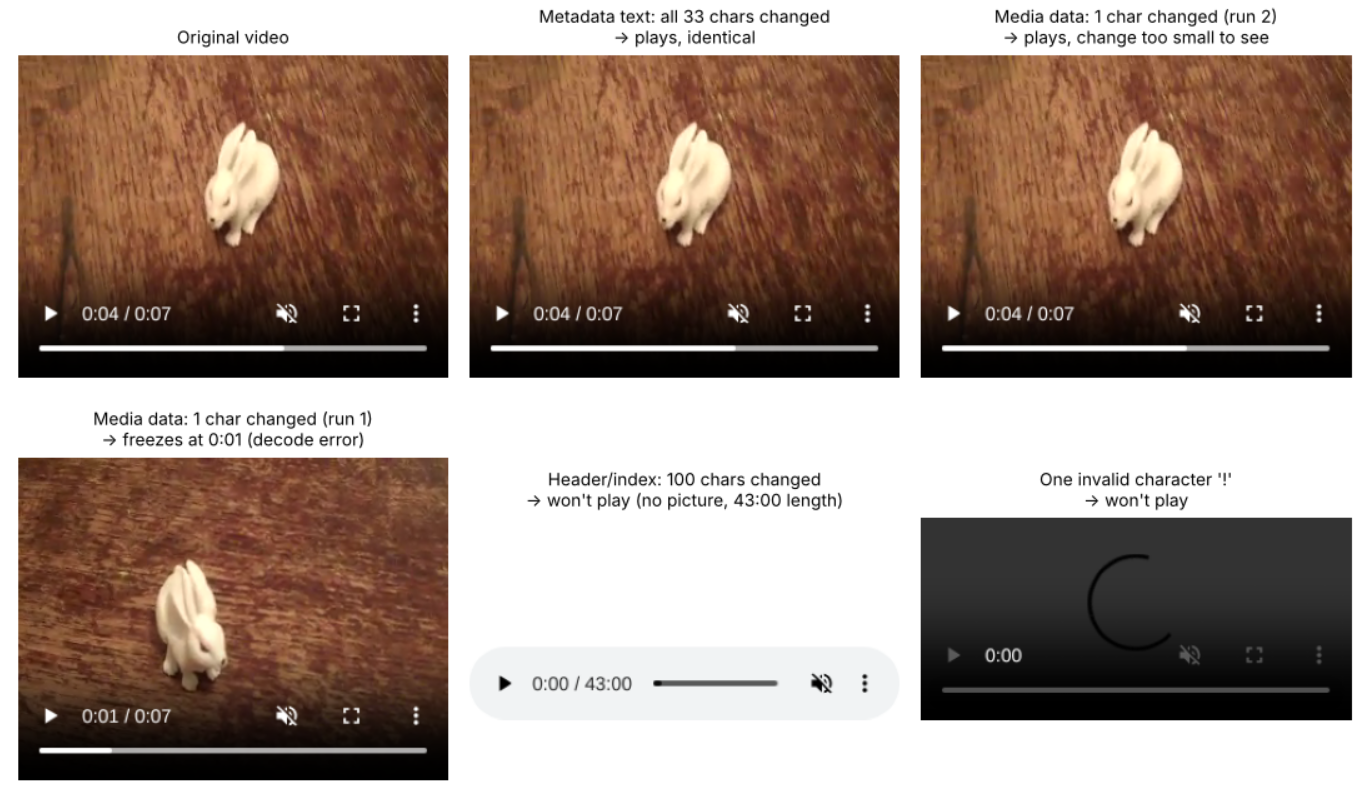

| Where the characters are changed | k = 1 | k = 10 | k = 100 |
|---|---|---|---|
| Header/index (`ftyp` + `moov`, first 0.5%) | 4 unaffected, 1 stops at 3.9 s | 2 play to the end, 3 fail | 5 **won't play** |
| Media data (`mdat`: video frames + audio) | 4 **freeze** after 1.2–3.8 s, 1 plays (change too small to see) | 5 freeze after 0.3–2.1 s | 5 **won't play** |
| Metadata text (`"Apple Video Media Handler"`) | 5 unaffected | 5 unaffected | all 33 chars: 5 unaffected |
| One invalid character (`!`) | base64 error, **won't play** | | |

  OpenCV (FFmpeg) is more forgiving: it hides decode errors and still decodes every media-data version, with 20–234 of the 234 frames changed.
- **How many can be altered without affecting the display?** It depends on *where*, not how many. Even **1** character in the frame data froze the video in 4 of 5 runs, so no change there is safe. Characters in non-critical bytes can all be changed with no visible effect: here all 33 characters of the metadata text (and 4 of 5 single changes in the header were also harmless).
- **Image:** Yes. `Image("f.png")` also stores **base64 of the file** (+33%), but bare, under its own key `"image/png": "iVBORw0KGgo…"`, not inside an HTML `<video>` tag. So it is the **same encoding (base64), different container**. Plots and pasted screenshots are stored the same way.

**Q2. Dictionaries, phone books, textbook index.** Yes, I have used both. Entries are sorted alphabetically, and the guide words at the top of each page let us jump close to the word and then narrow down (like binary search), instead of reading page by page.
1. **Printed dictionary:** Alphabetical word = **key**; definition = **value**.
2. **Phonebook:** Person's name = **key**; phone number = **value**.
3. **Google Form:** There are 2 ways to look into this problem.
    First from **Form perspective**: “IITK email” printed text is the **field/key**; the email address value we enter is its **value**.

    However, another way to interpret this from **Quiz perspective**: The IITK email ID value we enter is the key, a unique identifier for each respondent. Their answers, rank, scores, mistake counts, etc can be the values.
4. **Textbook index:** Topic = **key**; the integers are the **values**: the **page numbers** where the topic appears (one topic can have several pages).

**Q3. Data structures at work.** In ESP (electric submersible pump) production surveillance:
- **dict** `{well_id: readings}`: fast lookup of any well's data by its ID.
- **list**: the time-ordered daily readings (e.g. flow rate) of one well.
- **set**: unique alert types; removes duplicates and gives fast "is it present?" checks.
- **tuple**: fixed values that must not change, e.g. `(well_id, date)`; because it is immutable it can be a dict key.

In [1]:
well_readings = {'W1': [100, 98, 96], 'W2': [120, 118, 117]}        # dict of lists
unique_alerts = {'low_flow', 'low_flow', 'high_pressure'}              # set removes duplicates
daily_rate    = {('W1', '2026-10-01'): 100, ('W1', '2026-10-02'): 98}  # tuple as dict key
print('W1 latest rate:', well_readings['W1'][-1])
print('Unique alerts:', sorted(unique_alerts))
print('W1 rate on 2 Oct:', daily_rate[('W1', '2026-10-02')])

W1 latest rate: 96
Unique alerts: ['high_pressure', 'low_flow']
W1 rate on 2 Oct: 98


### Q1 experiment
Step 1 embeds the video. Step 2 changes k = 1, 10, 100 characters in three parts of the base64 text (5 random runs each), counts the changed frames with OpenCV, and shows one changed video per part so it can be played in the notebook. Step 3 embeds an image.

In [ ]:
# Step 1: embed the video and print what the notebook stores
import os, base64, random, urllib.request
os.environ["OPENCV_FFMPEG_LOGLEVEL"], os.environ["OPENCV_LOG_LEVEL"] = "-8", "SILENT"   # hide decoder warnings
import numpy as np, cv2
from IPython.display import Video, Image, HTML, display

VIDEO_URL  = "https://raw.githubusercontent.com/mdn/learning-area/main/html/multimedia-and-embedding/video-and-audio-content/rabbit320.mp4"
VIDEO_FILE = "rabbit320.mp4"
K_LIST     = [1, 10, 100]
N_TRIALS   = 5                                     # random repeats for each k
SHOW_K     = {"header/index": 100, "media data": 1, "metadata text": 100}   # version to play in the notebook
B64_CHARS  = "ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz0123456789+/"
random.seed(0)

urllib.request.urlretrieve(VIDEO_URL, VIDEO_FILE)
raw = open(VIDEO_FILE, "rb").read()
video = Video(VIDEO_FILE, embed=True, width=240)
display(video)
html = video._repr_html_()                         # exactly what is saved in the .ipynb
b64 = html.split("base64,")[1].split('"')[0]
print(html[:110].replace("\n", " "), "...")
print(f"{len(raw):,} bytes -> {len(b64):,} characters (x{len(b64) / len(raw):.2f})")
print("decodes back to the same file:", base64.b64decode(b64) == raw)

<video controls  width="240" >  <source src="data:video/mp4;base64,AAAAGGZ0eXBtcDQyAAAAAW1wNDJtcDQxAAARu21vb3Y ...
834,563 bytes -> 1,112,752 characters (x1.33)
decodes back to the same file: True


In [ ]:
# Step 2: change k characters in different parts of the text and check the video
def frames(data):                    # decode every frame of an MP4 (bytes)
    open("test.mp4", "wb").write(data)
    cap, out = cv2.VideoCapture("test.mp4"), []
    while True:
        ok, f = cap.read()
        if not ok: return out
        out.append(f)

def alter(s, k, lo, hi):             # replace k characters in s[lo:hi] with other valid base64 characters
    s = list(s)
    for i in random.sample(range(lo, hi), min(k, hi - lo)):
        s[i] = random.choice(B64_CHARS.replace(s[i], ""))
    return "".join(s)

def check(s):                        # what happens to the video?
    try: fr = frames(base64.b64decode(s, validate=True))
    except ValueError: return "base64 error"
    if not fr: return "won't play"
    return sum(not np.array_equal(a, b) for a, b in zip(fr, ORIGINAL)) + len(ORIGINAL) - len(fr)

def show(s):                         # display a changed video in the notebook
    display(HTML(f'<video controls width="240" src="data:video/mp4;base64,{s}"></video>'))

ORIGINAL = frames(raw)
chars = lambda a, b: (-(-4 * a // 3), 4 * b // 3)    # byte range -> base64 character range
text = raw.find(b"Apple Video Media Handler")
parts = {"header/index": chars(0, raw.find(b"free") - 4),          # ftyp + moov boxes
         "media data":   chars(raw.find(b"mdat") + 4, len(raw)),   # video frames + audio
         "metadata text": chars(text, text + 25)}
for name, (lo, hi) in parts.items():
    print(f"{name} ({hi - lo:,} chars), frames changed in {N_TRIALS} runs:")
    for k in K_LIST:
        runs = [alter(b64, k, lo, hi) for _ in range(N_TRIALS)]
        print(f"   k = {min(k, hi - lo):3}: {[check(r) for r in runs]}")
        if k == SHOW_K[name]: show(runs[0])            # play this version in the notebook

bad = b64[:len(b64) // 2] + "!" + b64[len(b64) // 2 + 1:]
show(bad)
print("one invalid character '!':", check(bad))

header/index (6,084 chars), frames changed in 5 runs:


   k =   1: [0, 0, 105, 0, 0]
   k =  10: [196, "won't play", "won't play", 210, "won't play"]
   k = 100: ["won't play", "won't play", "won't play", "won't play", "won't play"]


media data (1,106,634 chars), frames changed in 5 runs:


   k =   1: [100, 150, 20, 57, 23]


   k =  10: [159, 154, 207, 180, 172]


   k = 100: [234, 234, 234, 233, 234]
metadata text (33 chars), frames changed in 5 runs:


   k =   1: [0, 0, 0, 0, 0]


   k =  10: [0, 0, 0, 0, 0]


   k =  33: [0, 0, 0, 0, 0]


one invalid character '!': base64 error


**Screenshots:** Step 2 videos played in Chrome (the browser showing the notebook)

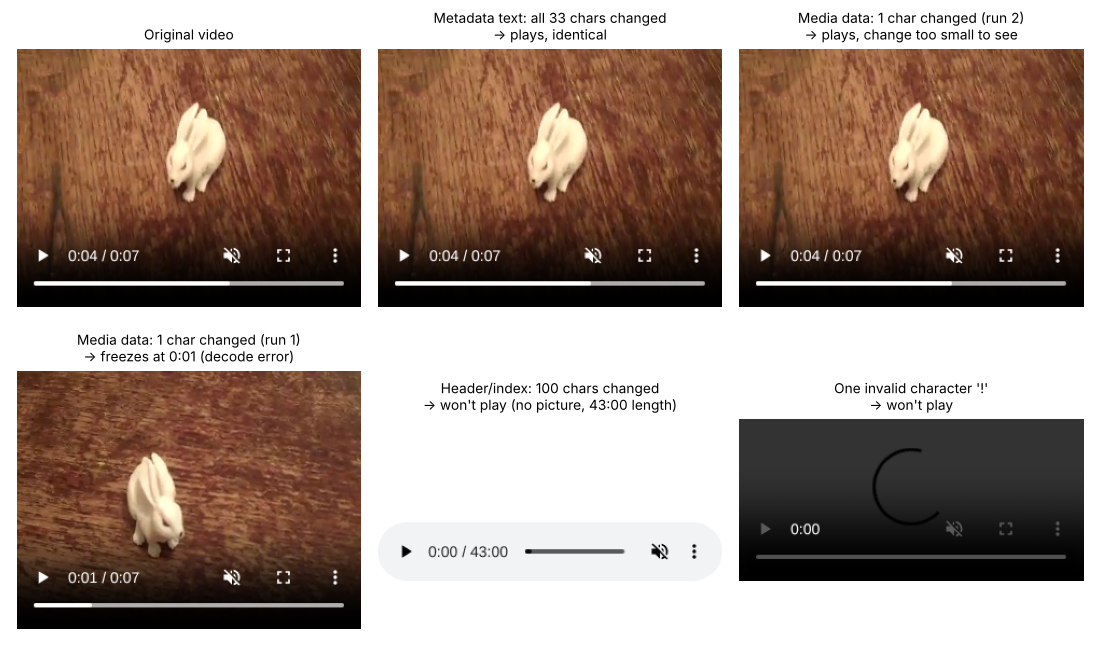

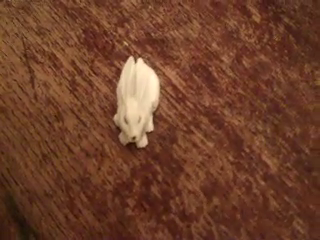

image -> image/png : iVBORw0KGgoAAAANSUhEUgAAAUAAAADwCAIAAAD+ ...
video -> text/html : <source src="data:video/mp4;base64,AAAAGGZ0eXBtcDQyAAA ...
image is base64 of the PNG file: True


In [4]:
# Step 3: embed an image and compare how it is stored with the video
cv2.imwrite("frame.png", ORIGINAL[100])
img = Image("frame.png", width=160)
display(img)
(key, value), = img._repr_mimebundle_()[0].items()   # what is saved in the .ipynb
print("image ->", key, ":", value[:40], "...")
print("video -> text/html :", html[html.find("<source"):][:54], "...")
print("image is base64 of the PNG file:", base64.b64decode(value) == open("frame.png", "rb").read())